# Pulse propagation in 2D (time domain from a frequency sweep)
After the pulse2d example of the MATLAB WaveSim implementation.

A plane-wave pulse (centre wavelength 1 μm, 5 fs Gaussian envelope) enters a homogeneous 2D
domain of 16 x 32 μm, absorbing along x and periodic along y. The time-domain field is
built from independent frequency-domain Helmholtz solves:

1. the pulse s(t) is sampled on a time grid t_n = n dt, n = 0..N-1;
2. its DFT S_k sits on the frequencies f_k = k / (N dt); every bin with |S_k| above
   1e-3 of the peak is solved at the vacuum wavelength c / f_k;
3. u(x, t_n) = (2 / N) Re sum_k S_k conj(U_k(x)) exp(+2πi k n / N). The solver's outgoing
   waves go as exp(+i k x), the exp(-iωt) convention, hence conj(U_k) with numpy's
   exp(+iωt) inverse transform.

Check: the |u|^2 peak, tracked over time, moves at the speed of light. The field is
animated as the pulse crosses the domain.

Size: 23 solves, each 0.019 Mvoxel including boundaries, 0.0004 GB of memory (service estimate).

In [1]:
import numpy as np
from time import time
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from wavesimpro import configure, simulate
from wsutils import output_dir

NAME = "hmhz_pulse2d"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

# Parameters
C_LIGHT = 0.299792458         # speed of light (μm/fs)
WAVELENGTH = 1.0              # centre wavelength in vacuum (μm)
PIXEL_SIZE = 0.2              # μm; 3.6 points per wavelength at the shortest solved (0.73 μm)
N_X, N_Y = 80, 160            # 16 μm along x (absorbing), 32 μm along y (periodic)
BOUNDARY_WIDTH = 4.0          # μm, added along x only

# Pulse and time grid
F0 = C_LIGHT / WAVELENGTH     # centre frequency (1/fs)
SIGMA_T = 5.0                 # Gaussian envelope (fs)
T_CENTER = 20.0               # envelope peak at the source (fs)
DT = 0.5                      # time step (fs)
N_T = 200                     # record of 100 fs; the pulse crosses 16 μm in 53 fs
KEEP = 1e-3                   # solve the bins with |S_k| above this fraction of the peak

t = np.arange(N_T) * DT
pulse = np.exp(-(t - T_CENTER) ** 2 / (2 * SIGMA_T ** 2)) * np.cos(2 * np.pi * F0 * (t - T_CENTER))
spectrum = np.fft.fft(pulse)
freqs = np.arange(N_T) / (N_T * DT)
bins = np.nonzero((freqs > 0) & (freqs < 0.5 / DT)
                  & (np.abs(spectrum) > KEEP * np.abs(spectrum).max()))[0]
f_solve = freqs[bins]
print(f"Record {N_T * DT:.0f} fs at dt = {DT} fs; {len(bins)} solves, wavelengths "
      f"{C_LIGHT / f_solve[-1]:.2f}-{C_LIGHT / f_solve[0]:.2f} um")

Record 100 fs at dt = 0.5 fs; 23 solves, wavelengths 0.73-1.58 um


In [2]:
# Homogeneous medium (vacuum) and a unit plane-wave sheet at the x-entry plane (x = 0).
permittivity = np.ones((N_X, N_Y, 1), dtype=np.complex64)
source_values = np.ones((1, N_Y, 1), dtype=np.complex64)
source_position = [0, 0, 0]  # in pixels

# One solve per frequency bin; periodic in y (and the singleton z), absorbing in x.
fields = np.zeros((len(bins), N_X, N_Y), dtype=np.complex64)
total_iterations = 0
start = time()
for k, f in enumerate(f_solve):
    print(f"Simulation: {k + 1}/{len(bins)}, wavelength {C_LIGHT / f:.3f} um")
    u, iterations, residual_norm = simulate(
        permittivity=permittivity,
        sources=[(source_values, source_position)],
        wavelength=C_LIGHT / f,
        pixel_size=PIXEL_SIZE,
        boundary_width=BOUNDARY_WIDTH,
        periodic=(False, True, True),
    )
    fields[k] = u  # u is a host numpy array of shape (N_X, N_Y)
    total_iterations += iterations
print(f"Total simulation time: {time() - start:.2f} s, {total_iterations} iterations")

Simulation: 1/23, wavelength 1.578 um

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 8bb7c328-6ed9-48f9-ab0f-29dfea6b0f79
  Version   : d733b69f-6b84-408b-9678-21941204cb17
  Command   : 93b5921a-8f9d-43dd-b040-18a8570f2909
  Mode      : Helmholtz (scalar)
  Domain    : 80x160x1 voxels  lambda=1.577855042105263 um  dx=0.200 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
Simulation: 2/23, wavelength 1.499 um

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 71ddd91c-8026-4e34-8b18-51c490573280
  Version   : 5cf3a862-a945-4a09-874f-7f850a58dce4
  Command   : 410d5b3d-9806-4cf3-b0b9-fd0ea5c17bbc
  Mode      : Helmholtz (scalar)
  Domain    : 80x160x1 voxels  lambda=1.49896229 um  

In [3]:
# Field in the time domain: weight each solve by the pulse spectrum and sum the bins.
weighted = np.conj(fields) * spectrum[bins, None, None].astype(np.complex64)


def synthesize(n):
    """u(x, y, t_n) for the time indices n: (2 / N) Re sum_k W_k exp(+2πi k n / N)."""
    phase = np.exp(2j * np.pi * np.outer(np.atleast_1d(n), bins) / N_T)
    return (2.0 / N_T) * np.real(phase @ weighted.reshape(len(bins), -1)).reshape((-1, N_X, N_Y))


# Speed check: x of the |u|^2 peak (the field is uniform in y) while the pulse is inside.
check_n = np.arange(int(30 / DT), int(65 / DT), int(5 / DT))
x_peak = (synthesize(check_n) ** 2).mean(axis=2).argmax(axis=1) * PIXEL_SIZE
speed = np.polyfit(check_n * DT, x_peak, 1)[0]
print("Pulse peak x (um): " + ", ".join(f"{n * DT:.0f} fs: {x:.1f}" for n, x in zip(check_n, x_peak)))
print(f"Pulse speed {speed:.4f} um/fs, c = {C_LIGHT:.4f} um/fs ({100 * (speed / C_LIGHT - 1):+.1f} %)")

Pulse peak x (um): 30 fs: 3.2, 35 fs: 4.2, 40 fs: 6.2, 45 fs: 7.2, 50 fs: 9.2, 55 fs: 10.2, 60 fs: 12.2
Pulse speed 0.3000 um/fs, c = 0.2998 um/fs (+0.1 %)


Saved animation to output/hmhz_pulse2d/hmhz_pulse2d.gif


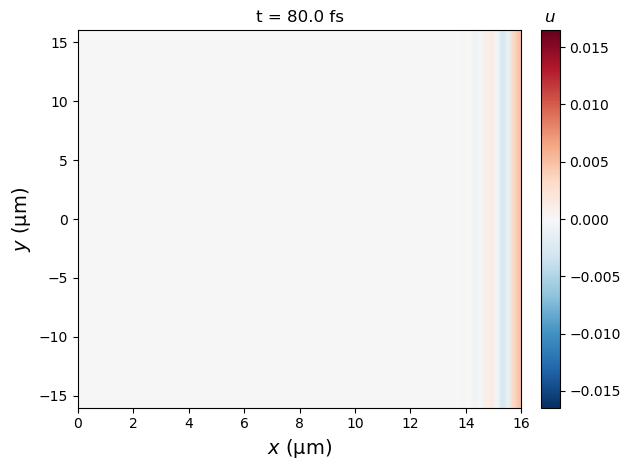

In [4]:
# Animate the field every 1 fs while the pulse crosses the domain.
frames_n = np.arange(int(10 / DT), int(80 / DT) + 1, int(1 / DT))
frames = synthesize(frames_n)
t_frames = frames_n * DT
vmax = np.abs(frames).max()

fig, ax = plt.subplots()
extent = [0, N_X * PIXEL_SIZE, -N_Y * PIXEL_SIZE / 2, N_Y * PIXEL_SIZE / 2]
# .T puts x on the horizontal axis and y on the vertical axis.
im = ax.imshow(frames[0].T, extent=extent, origin='lower',
               vmin=-vmax, vmax=vmax, cmap='RdBu_r', aspect='auto')
ax.set_xlabel(r"$x$ (μm)", fontsize=14)
ax.set_ylabel(r"$y$ (μm)", fontsize=14)
title = ax.set_title(f"t = {t_frames[0]:.1f} fs")
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_title(r"$u$")


def update(frame):
    im.set_data(frames[frame].T)
    title.set_text(f"t = {t_frames[frame]:.1f} fs")
    return im, title


anim = animation.FuncAnimation(fig, update, frames=len(frames_n), interval=100, blit=False)
plt.tight_layout()

# Save the animation as a GIF in OUTPUT_DIR.
gif_path = f"{OUTPUT_DIR}/{NAME}.gif"
try:
    anim.save(gif_path, writer=animation.PillowWriter(fps=10))
    print(f"Saved animation to output/{NAME}/{NAME}.gif")
except Exception as exc:  # noqa: BLE001 - saving is best-effort; still show the animation
    print(f"Could not save animation ({exc}).")

plt.show()